In [2]:
# import libraries 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Text(0.5, 0, 'X dataset')

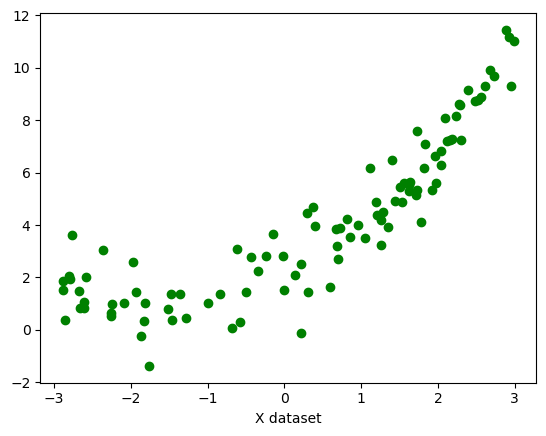

In [5]:
X = 6 * np.random.rand(100,1) - 3

y = 0.5 * X**2 + 1.5 * X + 2 + np.random.randn(100,1)

#quadratic equations used - y = 0.5 x^2 + 1.5x + 2 + outliers
plt.scatter(X ,y ,color = "g")

plt.xlabel("X dataset")

In [7]:
# this is not linear data set :

from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test =  train_test_split(X,y ,test_size =0.2 , 
                                                        random_state =42)


In [8]:
# lets implement simple linear regression 

from sklearn.linear_model import LinearRegression 
regression_1 = LinearRegression()

In [9]:
regression_1.fit(X_train , y_train)

LinearRegression()

In [10]:
from sklearn.metrics import r2_score

score = r2_score(y_test , regression_1.predict(X_test))

In [12]:
print(score)           # we are getting less accuraccy.

0.5978586367217765


Text(0, 0.5, 'y ')

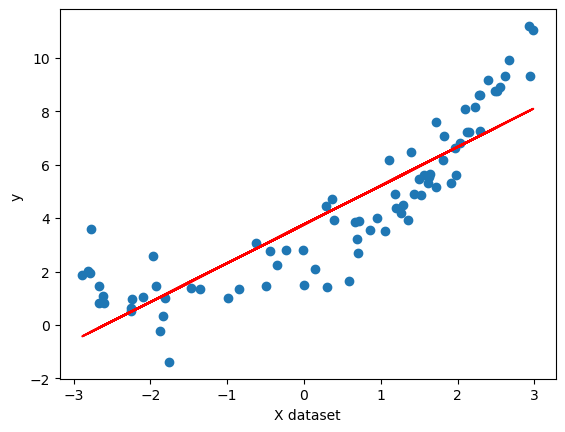

In [15]:
#  lets do visualization 

plt.plot(X_train , regression_1.predict(X_train) , color ="r")

plt.scatter(X_train ,y_train)
plt.xlabel("X dataset")
plt.ylabel("y ")

In [16]:
# is is showing error bcz we fit this from linear regression so lets see how to resolve it .


In [17]:
# lets apply polynomial transformation 
from sklearn.preprocessing import PolynomialFeatures

In [19]:
poly =  PolynomialFeatures( degree = 2 , include_bias =True)


In [25]:
X_train_poly  = poly.fit_transform(X_train)  # fit_transform : no reference of test data is taken .

X_test_poly = poly.transform(X_test)      # only transform

In [26]:
X_train_poly # her ewe have 3 column , first- 1 (bias) , second-  x1 (feature) , third -x1^2 (x1 square)

array([[ 1.00000000e+00,  2.94625310e+00,  8.68040731e+00],
       [ 1.00000000e+00,  6.70158194e-01,  4.49112005e-01],
       [ 1.00000000e+00, -8.44447622e-01,  7.13091787e-01],
       [ 1.00000000e+00,  2.92509145e+00,  8.55616000e+00],
       [ 1.00000000e+00, -1.81419901e+00,  3.29131803e+00],
       [ 1.00000000e+00, -1.93175793e+00,  3.73168871e+00],
       [ 1.00000000e+00,  3.92067135e-01,  1.53716638e-01],
       [ 1.00000000e+00, -3.46750949e-01,  1.20236220e-01],
       [ 1.00000000e+00,  2.61817630e+00,  6.85484716e+00],
       [ 1.00000000e+00,  3.68604453e-01,  1.35869243e-01],
       [ 1.00000000e+00, -2.88711445e+00,  8.33542985e+00],
       [ 1.00000000e+00, -1.47727878e+00,  2.18235260e+00],
       [ 1.00000000e+00,  1.71963390e+00,  2.95714076e+00],
       [ 1.00000000e+00,  1.10886753e+00,  1.22958721e+00],
       [ 1.00000000e+00,  2.48610033e+00,  6.18069484e+00],
       [ 1.00000000e+00, -2.78712395e+00,  7.76805990e+00],
       [ 1.00000000e+00,  1.35493991e+00

In [27]:
X_test_poly

array([[ 1.        , -0.1539118 ,  0.02368884],
       [ 1.        ,  1.77621915,  3.15495446],
       [ 1.        , -1.45943932,  2.12996314],
       [ 1.        ,  2.18569697,  4.77727126],
       [ 1.        ,  2.88306486,  8.31206297],
       [ 1.        , -2.8825196 ,  8.30891926],
       [ 1.        ,  1.25294975,  1.56988308],
       [ 1.        ,  2.04577592,  4.18519913],
       [ 1.        , -1.28745152,  1.65753142],
       [ 1.        ,  2.73563365,  7.48369148],
       [ 1.        ,  1.73092864,  2.99611396],
       [ 1.        , -1.52211776,  2.31684249],
       [ 1.        , -0.68878684,  0.47442732],
       [ 1.        ,  0.81424265,  0.66299109],
       [ 1.        , -2.35879883,  5.5639319 ],
       [ 1.        , -2.86214884,  8.19189596],
       [ 1.        ,  0.20959268,  0.04392909],
       [ 1.        , -0.57354926,  0.32895875],
       [ 1.        , -2.59066209,  6.71153007],
       [ 1.        ,  0.21694076,  0.04706329]])

In [29]:
# try apply same linear regresison
from sklearn.metrics import r2_score

regression  = LinearRegression()

regression.fit(X_train_poly , y_train)

y_pred = regression.predict(X_test_poly)

score = r2_score(y_test, y_pred)

print(score)

0.8520721416994665


from 0.59 to 0.85 : score has increased

In [31]:
# graph

print(regression.coef_)      # thre coeficient

[[0.         1.47476594 0.44211003]]


In [33]:
print(regression.intercept_)    # onyl 1 

[2.27214413]


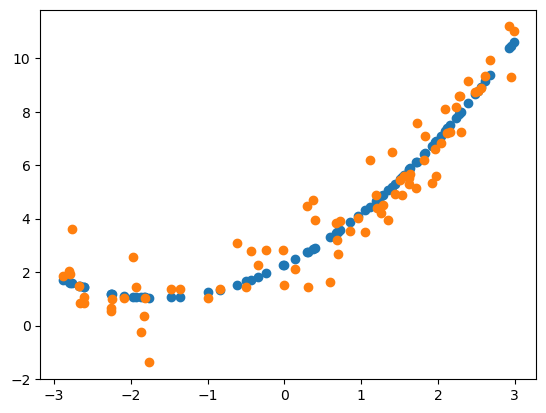

In [36]:
# lets take some new data and plot this 

plt.scatter(X_train , regression.predict(X_train_poly))
plt.scatter(X_train , y_train)

so this is how your best fit line occure

# if degree is 3 ? 

In [37]:
X_new = np.linspace(-3 ,3 ,200).reshape(200,1)
X_new_poly = poly.transform(X_new)

X_new_poly

array([[ 1.00000000e+00, -3.00000000e+00,  9.00000000e+00],
       [ 1.00000000e+00, -2.96984925e+00,  8.82000455e+00],
       [ 1.00000000e+00, -2.93969849e+00,  8.64182723e+00],
       [ 1.00000000e+00, -2.90954774e+00,  8.46546804e+00],
       [ 1.00000000e+00, -2.87939698e+00,  8.29092700e+00],
       [ 1.00000000e+00, -2.84924623e+00,  8.11820409e+00],
       [ 1.00000000e+00, -2.81909548e+00,  7.94729931e+00],
       [ 1.00000000e+00, -2.78894472e+00,  7.77821267e+00],
       [ 1.00000000e+00, -2.75879397e+00,  7.61094417e+00],
       [ 1.00000000e+00, -2.72864322e+00,  7.44549380e+00],
       [ 1.00000000e+00, -2.69849246e+00,  7.28186157e+00],
       [ 1.00000000e+00, -2.66834171e+00,  7.12004747e+00],
       [ 1.00000000e+00, -2.63819095e+00,  6.96005151e+00],
       [ 1.00000000e+00, -2.60804020e+00,  6.80187369e+00],
       [ 1.00000000e+00, -2.57788945e+00,  6.64551400e+00],
       [ 1.00000000e+00, -2.54773869e+00,  6.49097245e+00],
       [ 1.00000000e+00, -2.51758794e+00

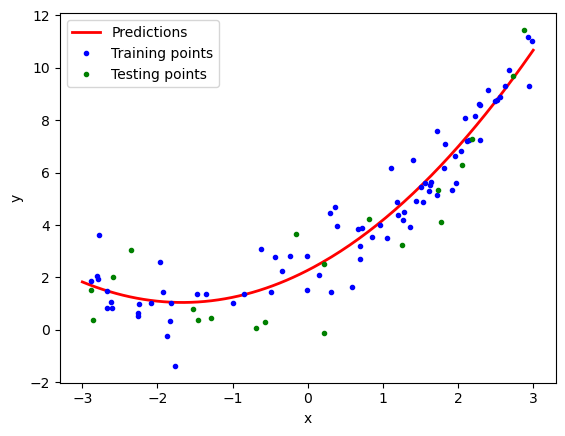

In [39]:
# use regression 
y_new  = regression.predict(X_new_poly)

plt.plot(X_new , y_new  , "r-" , linewidth = 2 , label = "Predictions")

plt.plot(X_train , y_train , "b." ,label = "Training points")

plt.plot(X_test , y_test , "g." , label = "Testing points")

plt.xlabel("x")

plt.ylabel("y")

plt.legend()
plt.show()

In [40]:
# we have implemented  same data with models with  different polynomial degree , and 
# best result is given by the model having degree 2 

# pipeline  concept

In [41]:
from sklearn.pipeline import Pipeline

In [48]:
def poly_regression(degree):
    
    X_new = np.linspace(-3 , 3,200).reshape(200 , 1)
    # The numpy.linspace function is used to create an array of evenly spaced values over a specified range.
    
    poly_features = PolynomialFeatures(degree = degree , include_bias = True )
    
    lin_reg = LinearRegression()
    
    poly_regression = Pipeline([
        ("poly_features",poly_features),
        ("lin_reg" , lin_reg)
    ])
    
    poly_regression.fit(X_train , y_train)
    
    y_pred_new  = poly_regression.predict(X_new)
    
    
    # plotting predicted the line
    
    plt.plot(X_new, y_pred_new,'r', label="Degree " + str(degree), linewidth=2)
    plt.plot(X_train, y_train, "b.", linewidth=3)
    plt.plot(X_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-4,4, 0, 10])
    plt.show()
    

* poly_features = PolynomialFeatures(degree = degree , include_bias = True )

PolynomialFeatures object from scikit-learn with the specified degree. This object will be used to transform the original features into polynomial features.

python

* lin_reg = LinearRegression()

This creates a linear regression model (LinearRegression from scikit-learn) that will be used to fit the polynomial features.


    
* poly_regression = Pipeline([
        ("poly_features",poly_features),
        ("lin_reg" , lin_reg)
    ])
    
You create a scikit-learn Pipeline object that consists of two steps:

first, it applies the polynomial feature transformation (poly_features), and 

then it fits a linear regression model (lin_reg) to the transformed data.
    
* poly_regression.fit(X_train , y_train)

This line fits the polynomial regression model to the training data X_train and y_train, where X_train are the input features, and y_train are the target values
    
* y_pred_new  = poly_regression.predict(X_new)
You use the trained polynomial regression model to make predictions on the new input data X_new, resulting in predicted values stored in y_pred_new.

    
 #plotting predicted the line
    
* plt.plot(X_new, y_pred_new,'r', label="Degree " + str(degree), linewidth=2)

This line plots the predicted values y_pred_new against the new input data X_new as a red line, and it includes a label indicating the degree of the polynomial being used for this plot.


* plt.plot(X_train, y_train, "b.", linewidth=3)
  plt.plot(X_test, y_test, "g.", linewidth=3)

  These lines plot the original training data points (X_train and y_train) as blue dots and the test data points (X_test and y_test) as green dots.


    

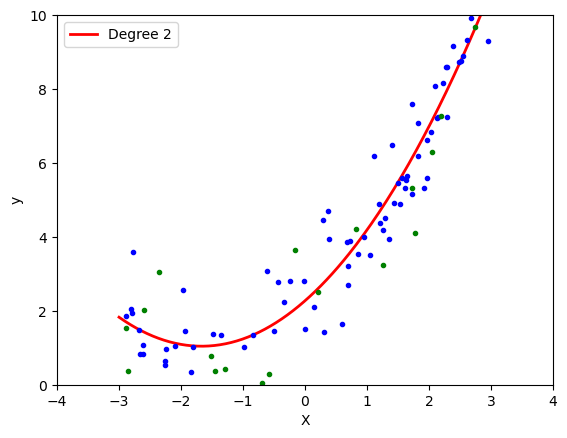

In [54]:
poly_regression(2)

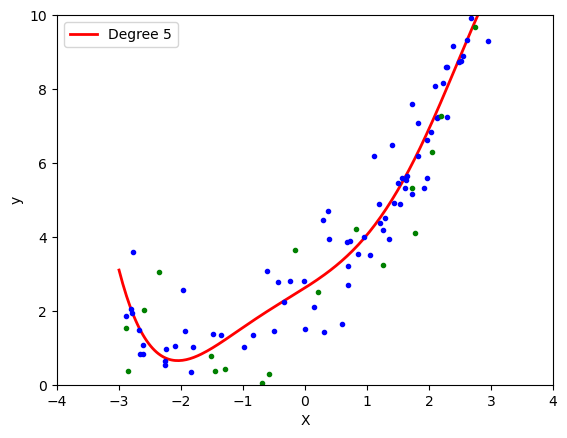

In [55]:
poly_regression(5)

In [56]:
# as we  increse degree model start overfitting each data point
